# **API data collection**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
import requests
import pandas as pd
url = "https://api.worldbank.org/v2/country/all/indicator/SP.POP.TOTL"

params = {
    "date": "2023",
    "format": "json",
    "per_page": 500
}
response = requests.get(url, params=params, timeout=30)
response.raise_for_status()
data = response.json()
print("HTTP status:", response.status_code)
print("Number of records:", len(data[1]))
print("First record:", data[1][0])

HTTP status: 200
Number of records: 266
First record: {'indicator': {'id': 'SP.POP.TOTL', 'value': 'Population, total'}, 'country': {'id': 'ZH', 'value': 'Africa Eastern and Southern'}, 'countryiso3code': 'AFE', 'date': '2023', 'value': 750491370, 'unit': '', 'obs_status': '', 'decimal': 0}


In [ ]:
df_population = pd.DataFrame(data[1])

df_population = pd.DataFrame({
    "Country": df_population["country"].apply(lambda x: x["value"]),
    "Country_Code": df_population["countryiso3code"],
    "Population": df_population["value"]
})

df_population.head()

,Country,Country_Code,Population
0,Africa Eastern and Southern,AFE,750491370.0
1,Africa Western and Central,AFW,508318102.0
2,Arab World,ARB,482105978.0
3,Caribbean small states,CSS,4519904.0
4,Central Europe and the Baltics,CEB,100183707.0


In [ ]:
gdp_url = "https://api.worldbank.org/v2/country/all/indicator/NY.GDP.PCAP.CD"

gdp_response = requests.get(gdp_url, params=params, timeout=30)
gdp_response.raise_for_status()

gdp_data = gdp_response.json()

df_gdp = pd.DataFrame(gdp_data[1])

df_gdp = pd.DataFrame({
    "Country_Code": df_gdp["countryiso3code"],
    "GDP_per_capita": df_gdp["value"]
})
df_gdp.head()

,Country_Code,GDP_per_capita
0,AFE,1571.132704
1,AFW,1846.246811
2,ARB,7504.356377
3,CSS,17609.682707
4,CEB,22693.950447


In [ ]:
life_url = "https://api.worldbank.org/v2/country/all/indicator/SP.DYN.LE00.IN"

life_response = requests.get(life_url, params=params, timeout=30)
life_response.raise_for_status()

life_data = life_response.json()

df_life = pd.DataFrame(life_data[1])

df_life = pd.DataFrame({
    "Country_Code": df_life["countryiso3code"],
    "Life_expectancy": df_life["value"]
})

df_life.head()

,Country_Code,Life_expectancy
0,AFE,65.146228
1,AFW,58.847483
2,ARB,72.444678
3,CSS,73.171645
4,CEB,77.758038


In [ ]:
df_api = df_population.merge(
    df_gdp,
    on="Country_Code",
    how="left"
)

df_api = df_api.merge(
    df_life,
    on="Country_Code",
    how="left"
)
df_api.head()

,Country,Country_Code,Population,GDP_per_capita,Life_expectancy
0,Africa Eastern and Southern,AFE,750491370.0,1571.132704,65.146228
1,Africa Western and Central,AFW,508318102.0,1846.246811,58.847483
2,Arab World,ARB,482105978.0,7504.356377,72.444678
3,Caribbean small states,CSS,4519904.0,17609.682707,73.171645
4,Central Europe and the Baltics,CEB,100183707.0,22693.950447,77.758038


In [ ]:
countries_url = "https://api.worldbank.org/v2/country"

countries_params = {
    "format": "json",
    "per_page": 500
}
countries_response = requests.get(
    countries_url,
    params=countries_params,
    timeout=30
)
countries_response.raise_for_status()

countries_data = countries_response.json()[1]
df_countries = pd.DataFrame(countries_data)

valid_codes = df_countries.loc[
    df_countries["region"].apply(
        lambda x: x["value"] != "Aggregates"
    ),
    "id"
]
df_api = df_api[
    df_api["Country_Code"].isin(valid_codes)
].copy()

df_api = df_api.reset_index(drop=True)

print("Number of countries:", len(df_api))
df_api.head()

Number of countries: 217


,Country,Country_Code,Population,GDP_per_capita,Life_expectancy
0,Afghanistan,AFG,41454761.0,413.757895,66.035
1,Albania,ALB,2411658.0,9740.702341,79.602
2,Algeria,DZA,46164219.0,5370.477235,76.261
3,American Samoa,ASM,47521.0,NaN,72.852
4,Andorra,AND,80856.0,46812.448450,84.041


In [ ]:
print("Dataset shape:", df_api.shape)
print("\nMissing values:")
print(df_api.isnull().sum())
print("\nDuplicates:", df_api.duplicated().sum())
print("\nData types:")
print(df_api.dtypes)

Dataset shape: (217, 5)

Missing values:
Country             0
Country_Code        0
Population          0
GDP_per_capita     13
Life_expectancy     0
dtype: int64

Duplicates: 0

Data types:
Country             object
Country_Code        object
Population         float64
GDP_per_capita     float64
Life_expectancy    float64
dtype: object


In [ ]:
df_api = df_api.dropna(
    subset=["GDP_per_capita"]
).copy()

df_api = df_api.drop_duplicates(
    subset=["Country_Code"]
)
df_api = df_api.reset_index(drop=True)
print("Dataset after cleaning:", df_api.shape)
print("\nMissing values:")
print(df_api.isnull().sum())
df_api.head()

Dataset after cleaning: (204, 5)

Missing values:
Country            0
Country_Code       0
Population         0
GDP_per_capita     0
Life_expectancy    0
dtype: int64


,Country,Country_Code,Population,GDP_per_capita,Life_expectancy
0,Afghanistan,AFG,41454761.0,413.757895,66.035
1,Albania,ALB,2411658.0,9740.702341,79.602
2,Algeria,DZA,46164219.0,5370.477235,76.261
3,Andorra,AND,80856.0,46812.448450,84.041
4,Angola,AGO,36749906.0,2885.513491,64.617


In [ ]:
df_api.to_csv("world_bank_cleaned_2023.csv", index=False)
print("CSV file saved successfully!")
print("Final dataset shape:", df_api.shape)
df_api.sample(5, random_state=42)

CSV file saved successfully!
Final dataset shape: (204, 5)


,Country,Country_Code,Population,GDP_per_capita,Life_expectancy
15,Barbados,BRB,282336.0,25583.872230,76.17800
9,Australia,AUS,26659922.0,65058.377315,83.05122
115,Mali,MLI,23769127.0,1042.442234,60.43900
78,Haiti,HTI,11637398.0,1681.844077,64.93600
66,Gabon,GAB,2484789.0,7802.824333,68.33700


# **Web Scrapping**

In [ ]:
import requests
import pandas as pd
from bs4 import BeautifulSoup
from urllib.robotparser import RobotFileParser

wiki_url = "https://en.wikipedia.org/wiki/World_Happiness_Report"
headers = {"User-Agent": "KBTU-DataCollection-Project/1.0 (student project)"}

robots_response = requests.get("https://en.wikipedia.org/robots.txt", headers=headers, timeout=30)
robots_parser = RobotFileParser()
robots_parser.parse(robots_response.text.splitlines())

print("robots.txt status:", robots_response.status_code)
print("Scraping allowed:", robots_parser.can_fetch(headers["User-Agent"], wiki_url))

robots.txt status: 200
Scraping allowed: True


In [ ]:
wiki_response = requests.get(wiki_url, headers=headers, timeout=30)
wiki_response.raise_for_status()

soup = BeautifulSoup(wiki_response.text, "html.parser")

print("HTTP status:", wiki_response.status_code)
print("Page size (characters):", len(wiki_response.text))
print("Page title:", soup.title.get_text())

HTTP status: 200
Page size (characters): 3404901
Page title: World Happiness Report - Wikipedia


In [ ]:
tables = soup.find_all("table", class_="wikitable")
print("Number of wikitables on the page:", len(tables))

for i, table in enumerate(tables):
    first_row = table.find("tr")
    if first_row is None:
        continue
    header = [th.get_text(strip=True) for th in first_row.find_all("th")]
    print(i, header[:5])

Number of wikitables on the page: 13
0 ['Rank', 'Country or region', 'Life evaluation', 'GDP per capita', 'Social support']
1 ['Rank', 'Country or region', 'Life evaluation', 'GDP per capita', 'Social support']
2 ['Rank', 'Country or region', 'Life evaluation']
3 ['Rank', 'Country or region']
4 ['Rank', 'Country or region']
5 ['Rank', 'Country or region', 'Life evaluation', 'GDP per capita', 'Social support']
6 ['Rank', 'Country or region', 'Life evaluation', 'GDP per capita', 'Social support']
7 ['Rank', 'Country or region', 'Life evaluation', 'GDP per capita', 'Social support']
8 ['Rank', 'Change in rank', 'Country', 'Life evaluation', 'Change in score']
9 ['Rank', 'Country', 'Life evaluation', 'Change fromprior year', 'GDP per capita']
10 ['Rank[30]', 'Country', 'Life evaluation']
11 ['Overall rank', 'Country or region', 'Life evaluation']
12 ['Overall rank', 'Country or region', 'Life evaluation']


In [ ]:
report_heading = soup.find(id="2024_report")

if report_heading is None:
    raise ValueError("Section '2024 report' not found")

happiness_table = report_heading.find_next("table", class_="wikitable")

header = [th.get_text(strip=True) for th in happiness_table.find("tr").find_all("th")]
print("Section:", report_heading.get_text(strip=True))
print("Table columns:", header)
print("Number of rows:", len(happiness_table.find_all("tr")) - 1)

Section: 2024 report
Table columns: ['Rank', 'Country or region', 'Life evaluation']
Number of rows: 143


In [ ]:
rows = []

for tr in happiness_table.find_all("tr")[1:]:
    cells = [cell.get_text(strip=True) for cell in tr.find_all(["td", "th"])]
    if len(cells) >= 3:
        rows.append({
            "Rank": cells[0],
            "Country": cells[1],
            "Happiness": cells[2]
        })

df_happiness = pd.DataFrame(rows)
df_happiness.head(10)

,Rank,Country,Happiness
0,1,Finland,7.741
1,2,Denmark,7.583
2,3,Iceland,7.525
3,4,Sweden,7.344
4,5,Israel,7.341
5,6,Netherlands,7.319
6,7,Norway,7.302
7,8,Luxembourg,7.122
8,9,Switzerland,7.060
9,10,Australia,7.057


In [ ]:
print("Dataset shape:", df_happiness.shape)
print("\nMissing values:")
print(df_happiness.isnull().sum())
print("\nDuplicates:", df_happiness.duplicated(subset=["Country"]).sum())
print("\nData types:")
print(df_happiness.dtypes)

Dataset shape: (143, 3)

Missing values:
Rank         0
Country      0
Happiness    0
dtype: int64

Duplicates: 0

Data types:
Rank         object
Country      object
Happiness    object
dtype: object


In [ ]:
df_happiness["Country"] = (
    df_happiness["Country"]
    .str.replace(r"\[.*?\]", "", regex=True)
    .str.replace("*", "", regex=False)
    .str.strip()
)
df_happiness["Happiness"] = pd.to_numeric(df_happiness["Happiness"], errors="coerce")
df_happiness["Rank"] = pd.to_numeric(df_happiness["Rank"], errors="coerce").astype("Int64")

df_happiness = df_happiness.dropna(subset=["Happiness"])
df_happiness = df_happiness.drop_duplicates(subset=["Country"])
df_happiness = df_happiness.reset_index(drop=True)

print("Dataset after cleaning:", df_happiness.shape)
print("\nData types:")
print(df_happiness.dtypes)

Dataset after cleaning: (143, 3)

Data types:
Rank           Int64
Country       object
Happiness    float64
dtype: object


In [ ]:
print("Score range:", df_happiness["Happiness"].min(), "-", df_happiness["Happiness"].max())
print("All scores between 0 and 10:", df_happiness["Happiness"].between(0, 10).all())

df_happiness["Happiness_Level"] = pd.cut(
    df_happiness["Happiness"],
    bins=[0, 4.5, 6, 10],
    labels=["Low", "Medium", "High"]
)

print("\nCountries by happiness level:")
print(df_happiness["Happiness_Level"].value_counts())

print("\nTop 5 happiest countries:")
print(df_happiness.head(5).to_string(index=False))

print("\nTop 5 least happy countries:")
print(df_happiness.tail(5).to_string(index=False))

Score range: 1.721 - 7.741
All scores between 0 and 10: True

Countries by happiness level:
Happiness_Level
High      56
Medium    55
Low       32
Name: count, dtype: int64

Top 5 happiest countries:
 Rank Country  Happiness Happiness_Level
    1 Finland      7.741            High
    2 Denmark      7.583            High
    3 Iceland      7.525            High
    4  Sweden      7.344            High
    5  Israel      7.341            High

Top 5 least happy countries:
 Rank          Country  Happiness Happiness_Level
  139 Congo (Kinshasa)      3.295             Low
  140     Sierra Leone      3.245             Low
  141          Lesotho      3.186             Low
  142          Lebanon      2.707             Low
  143      Afghanistan      1.721             Low


In [ ]:
country_name_map = {
    "Russia": "Russian Federation",
    "Turkey": "Turkiye",
    "South Korea": "Korea, Rep.",
    "Iran": "Iran, Islamic Rep.",
    "Egypt": "Egypt, Arab Rep.",
    "Venezuela": "Venezuela, RB",
    "Laos": "Lao PDR",
    "Kyrgyzstan": "Kyrgyz Republic",
    "Slovakia": "Slovak Republic",
    "Vietnam": "Viet Nam",
    "Yemen": "Yemen, Rep.",
    "Gambia": "Gambia, The",
    "Ivory Coast": "Cote d'Ivoire",
    "Hong Kong": "Hong Kong SAR, China",
    "Congo (Brazzaville)": "Congo, Rep.",
    "Congo (Kinshasa)": "Congo, Dem. Rep.",
    "State of Palestine": "West Bank and Gaza"
}

df_happiness["Country"] = df_happiness["Country"].replace(country_name_map)

if "df_api" in globals():
    unmatched = df_happiness.loc[~df_happiness["Country"].isin(df_api["Country"]), "Country"]
    print("Countries not found in World Bank data:", len(unmatched))
    print(unmatched.tolist())

Countries not found in World Bank data: 2
['Taiwan', 'Yemen, Rep.']


In [ ]:
df_happiness.to_csv("happiness_2024_cleaned.csv", index=False)

print("CSV file saved successfully!")
print("Final dataset shape:", df_happiness.shape)
df_happiness.sample(5, random_state=42)

CSV file saved successfully!
Final dataset shape: (143, 4)


,Rank,Country,Happiness,Happiness_Level
117,118,Myanmar,4.354,Low
19,20,United Kingdom,6.749,High
82,83,South Africa,5.422,Medium
97,98,Turkiye,4.975,Medium
56,57,Paraguay,5.977,Medium


# **Data Analysis**

In [ ]:
import re
import unicodedata
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display


if "df_api" not in globals() or "df_happiness" not in globals():
    raise NameError("Run the API Data Collection and Web Scraping sections before Data Analysis.")

required_api_columns = {"Country", "Population", "GDP_per_capita", "Life_expectancy"}
required_happiness_columns = {"Country", "Happiness"}
missing_api_columns = required_api_columns.difference(df_api.columns)
missing_happiness_columns = required_happiness_columns.difference(df_happiness.columns)
if missing_api_columns or missing_happiness_columns:
    raise ValueError(
        f"Missing columns — df_api: {sorted(missing_api_columns)}; "
        f"df_happiness: {sorted(missing_happiness_columns)}"
    )

def normalize_country_name(country):
    """Create a comparison key without overwriting the displayed country name."""
    if pd.isna(country):
        return ""
    country = unicodedata.normalize("NFKD", str(country))
    country = country.encode("ascii", "ignore").decode("ascii")
    country = country.casefold().replace("&", " and ")
    country = re.sub(r"[^a-z0-9]+", " ", country)
    return re.sub(r"\s+", " ", country).strip()

api_for_merge = df_api.copy().rename(columns={"Country": "Country_WorldBank"})
happiness_for_merge = df_happiness.copy().rename(columns={"Country": "Country_Happiness"})
api_for_merge["Country_key"] = api_for_merge["Country_WorldBank"].map(normalize_country_name)
happiness_for_merge["Country_key"] = happiness_for_merge["Country_Happiness"].map(normalize_country_name)


api_key_duplicates = api_for_merge["Country_key"].duplicated().sum()
happiness_key_duplicates = happiness_for_merge["Country_key"].duplicated().sum()
print("Duplicate normalized country keys — World Bank:", api_key_duplicates)
print("Duplicate normalized country keys — Happiness:", happiness_key_duplicates)

df_merge_check = api_for_merge.merge(
    happiness_for_merge,
    on="Country_key",
    how="outer",
    indicator=True,
    validate="one_to_one"
)
df_merge_check["Country"] = df_merge_check["Country_WorldBank"].combine_first(
    df_merge_check["Country_Happiness"]
)

merge_counts = df_merge_check["_merge"].value_counts()
matched_count = int(merge_counts.get("both", 0))
only_world_bank_count = int(merge_counts.get("left_only", 0))
only_happiness_count = int(merge_counts.get("right_only", 0))
print("\nCountry matching results:")
display(pd.DataFrame({
    "Result": ["World Bank only", "Happiness only", "Matched in both datasets"],
    "Number of countries": [only_world_bank_count, only_happiness_count, matched_count]
}))

world_bank_unmatched = (
    df_merge_check.loc[df_merge_check["_merge"].eq("left_only"), "Country_WorldBank"]
    .dropna().sort_values().reset_index(drop=True)
)
happiness_unmatched = (
    df_merge_check.loc[df_merge_check["_merge"].eq("right_only"), "Country_Happiness"]
    .dropna().sort_values().reset_index(drop=True)
)
print("Countries found only in World Bank (first 30):")
display(world_bank_unmatched.head(30).to_frame(name="Country"))
print("Countries found only in Happiness data (first 30):")
display(happiness_unmatched.head(30).to_frame(name="Country"))


df_merged = df_merge_check.loc[df_merge_check["_merge"].eq("both")].copy()
if df_merged.empty:
    raise ValueError("No countries matched. Review the unmatched country lists and update country_name_map.")
df_merged = df_merged.drop(columns=["Country_key", "_merge"]).reset_index(drop=True)
print("\nMerged dataset shape:", df_merged.shape)
display(df_merged.head())

Duplicate normalized country keys — World Bank: 0
Duplicate normalized country keys — Happiness: 0

Country matching results:


,Result,Number of countries
0,World Bank only,63
1,Happiness only,2
2,Matched in both datasets,141


Countries found only in World Bank (first 30):


,Country
0,Andorra
1,Angola
2,Antigua and Barbuda
3,Aruba
4,"Bahamas, The"
5,Barbados
6,Belarus
7,Belize
8,Bermuda
9,Bhutan


Countries found only in Happiness data (first 30):


,Country
0,Taiwan
1,"Yemen, Rep."



Merged dataset shape: (141, 10)


,Country_WorldBank,Country_Code,Population,GDP_per_capita,Life_expectancy,Rank,Country_Happiness,Happiness,Happiness_Level,Country
0,Afghanistan,AFG,41454761.0,413.757895,66.035000,143,Afghanistan,1.721,Low,Afghanistan
1,Albania,ALB,2411658.0,9740.702341,79.602000,87,Albania,5.304,Medium,Albania
2,Algeria,DZA,46164219.0,5370.477235,76.261000,85,Algeria,5.364,Medium,Algeria
3,Argentina,ARG,45538401.0,14261.846567,77.395000,48,Argentina,6.188,High,Argentina
4,Armenia,ARM,2964300.0,8159.087210,77.465854,82,Armenia,5.455,Medium,Armenia


In [ ]:
analysis_columns = [
    "Population", "GDP_per_capita", "Life_expectancy", "Happiness"
]
analysis_columns = [column for column in analysis_columns if column in df_merged.columns]
df_numeric = df_merged[analysis_columns].apply(pd.to_numeric, errors="coerce")

print("Merged data shape:", df_merged.shape)
print("\nData types:")
display(df_merged.dtypes.to_frame(name="Data type"))

print("\nMissing values:")
missing_summary = pd.DataFrame({
    "Missing values": df_merged.isna().sum(),
    "Missing (%)": (df_merged.isna().mean() * 100).round(2)
}).sort_values("Missing (%)", ascending=False)
display(missing_summary)

print("Duplicate rows:", int(df_merged.duplicated().sum()))
print("Duplicate country names:", int(df_merged["Country"].duplicated().sum()))

print("\nDescriptive statistics (describe):")
display(df_numeric.describe().T.round(2))

print("\nMean, median, minimum, and maximum:")
summary_stats = pd.DataFrame({
    "Mean": df_numeric.mean(),
    "Median": df_numeric.median(),
    "Min": df_numeric.min(),
    "Max": df_numeric.max()
})
display(summary_stats.round(2))

Merged data shape: (141, 10)

Data types:


,Data type
Country_WorldBank,object
Country_Code,object
Population,float64
GDP_per_capita,float64
Life_expectancy,float64
Rank,Int64
Country_Happiness,object
Happiness,float64
Happiness_Level,category
Country,object



Missing values:


,Missing values,Missing (%)
Country_WorldBank,0,0.0
Country_Code,0,0.0
Population,0,0.0
GDP_per_capita,0,0.0
Life_expectancy,0,0.0
Rank,0,0.0
Country_Happiness,0,0.0
Happiness,0,0.0
Happiness_Level,0,0.0
Country,0,0.0


Duplicate rows: 0
Duplicate country names: 0

Descriptive statistics (describe):


,count,mean,std,min,25%,50%,75%,max
Population,141.0,54734684.87,1.738946e+08,385663.00,5311538.00,12200431.00,40049088.00,1.438070e+09
GDP_per_capita,141.0,18941.27,2.523914e+04,413.76,2434.45,7133.03,27634.62,1.332306e+05
Life_expectancy,141.0,73.94,7.250000e+00,54.46,68.48,75.31,79.60,8.525000e+01
Happiness,141.0,5.53,1.160000e+00,1.72,4.80,5.78,6.41,7.740000e+00



Mean, median, minimum, and maximum:


,Mean,Median,Min,Max
Population,54734684.87,12200431.00,385663.00,1.438070e+09
GDP_per_capita,18941.27,7133.03,413.76,1.332306e+05
Life_expectancy,73.94,75.31,54.46,8.525000e+01
Happiness,5.53,5.78,1.72,7.740000e+00


Correlation: Population, GDP per capita, Life expectancy


,Population,GDP_per_capita,Life_expectancy
Population,1.000,-0.067,-0.018
GDP_per_capita,-0.067,1.000,0.680
Life_expectancy,-0.018,0.680,1.000


Correlation matrix including Happiness:


,Population,GDP_per_capita,Life_expectancy,Happiness
Population,1.000,-0.067,-0.018,-0.073
GDP_per_capita,-0.067,1.000,0.680,0.669
Life_expectancy,-0.018,0.680,1.000,0.729
Happiness,-0.073,0.669,0.729,1.000


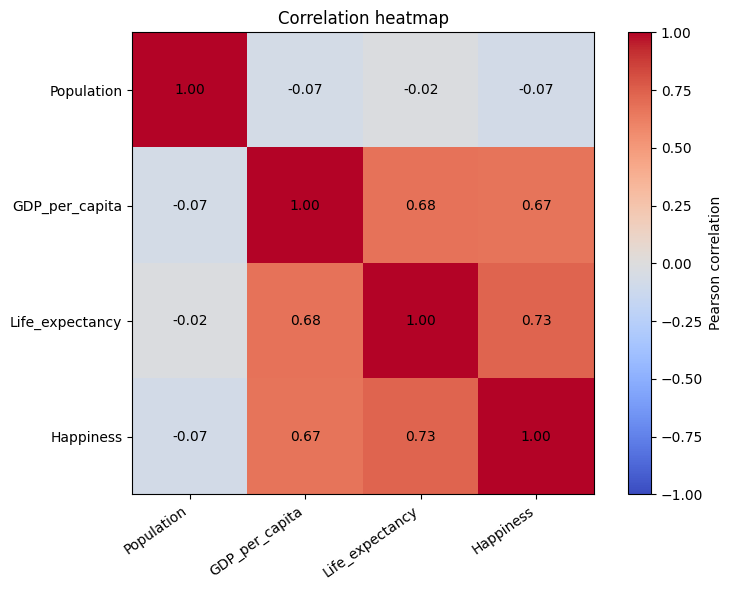

In [ ]:
core_corr_columns = ["Population", "GDP_per_capita", "Life_expectancy"]
core_corr_columns = [column for column in core_corr_columns if column in df_merged.columns]
core_correlation = df_merged[core_corr_columns].apply(pd.to_numeric, errors="coerce").corr()
print("Correlation: Population, GDP per capita, Life expectancy")
display(core_correlation.round(3))

corr_columns = [column for column in core_corr_columns + ["Happiness"] if column in df_merged.columns]
correlation_matrix = df_merged[corr_columns].apply(pd.to_numeric, errors="coerce").corr()
print("Correlation matrix including Happiness:")
display(correlation_matrix.round(3))

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(correlation_matrix, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(correlation_matrix.columns)))
ax.set_yticks(range(len(correlation_matrix.index)))
ax.set_xticklabels(correlation_matrix.columns, rotation=35, ha="right")
ax.set_yticklabels(correlation_matrix.index)
for row in range(len(correlation_matrix.index)):
    for col in range(len(correlation_matrix.columns)):
        value = correlation_matrix.iloc[row, col]
        if pd.notna(value):
            ax.text(col, row, f"{value:.2f}", ha="center", va="center", color="black")
ax.set_title("Correlation heatmap")
fig.colorbar(image, ax=ax, label="Pearson correlation")
fig.tight_layout()
plt.show()

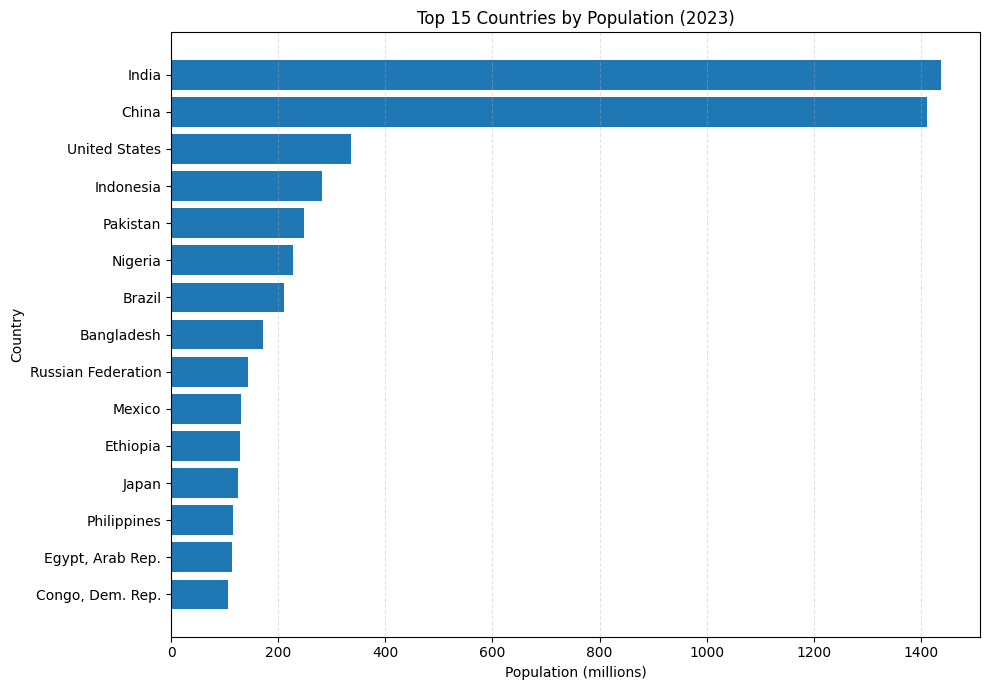

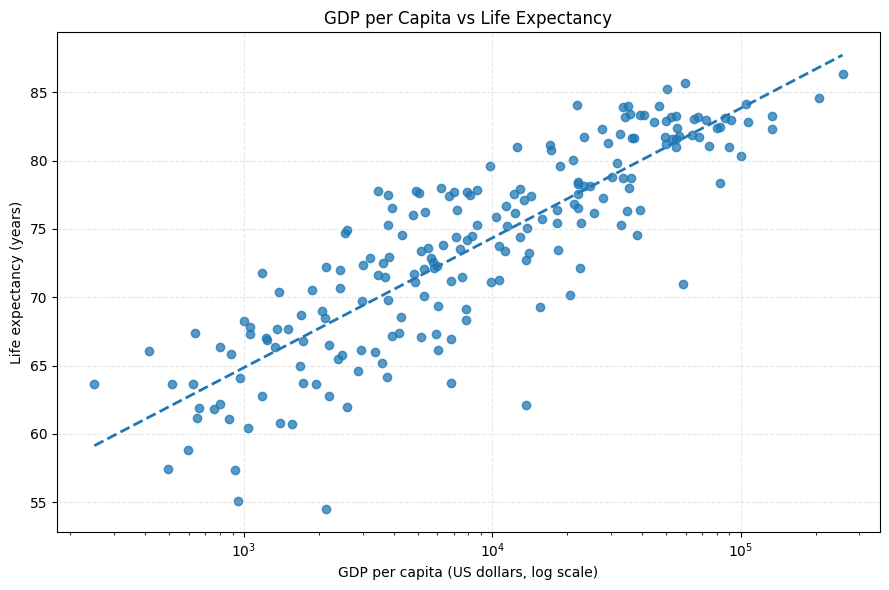

In [ ]:
# Population by country — top 15 in the World Bank dataset.
population_plot_data = df_api[["Country", "Population"]].copy()
population_plot_data["Population"] = pd.to_numeric(population_plot_data["Population"], errors="coerce")
population_plot_data = population_plot_data.dropna().nlargest(15, "Population").sort_values("Population")

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(population_plot_data["Country"], population_plot_data["Population"] / 1_000_000)
ax.set_title("Top 15 Countries by Population (2023)")
ax.set_xlabel("Population (millions)")
ax.set_ylabel("Country")
ax.grid(axis="x", linestyle="--", alpha=0.35)
fig.tight_layout()
plt.show()


scatter_data = df_api[["Country", "GDP_per_capita", "Life_expectancy"]].copy()
for column in ["GDP_per_capita", "Life_expectancy"]:
    scatter_data[column] = pd.to_numeric(scatter_data[column], errors="coerce")
scatter_data = scatter_data.dropna(subset=["GDP_per_capita", "Life_expectancy"])
scatter_data = scatter_data[(scatter_data["GDP_per_capita"] > 0) & (scatter_data["Life_expectancy"] > 0)]

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(scatter_data["GDP_per_capita"], scatter_data["Life_expectancy"], alpha=0.75)
ax.set_xscale("log")
ax.set_title("GDP per Capita vs Life Expectancy")
ax.set_xlabel("GDP per capita (US dollars, log scale)")
ax.set_ylabel("Life expectancy (years)")
ax.grid(True, linestyle="--", alpha=0.3)


if len(scatter_data) >= 2:
    x_log = np.log10(scatter_data["GDP_per_capita"].to_numpy())
    y_values = scatter_data["Life_expectancy"].to_numpy()
    slope, intercept = np.polyfit(x_log, y_values, 1)
    order = np.argsort(x_log)
    ax.plot(10 ** x_log[order], intercept + slope * x_log[order], linestyle="--", linewidth=2)
fig.tight_layout()
plt.show()

Happiness score summary:


,Happiness score
count,141.00
mean,5.53
std,1.16
min,1.72
25%,4.80
50%,5.78
75%,6.41
max,7.74


Scores between 0 and 10: True


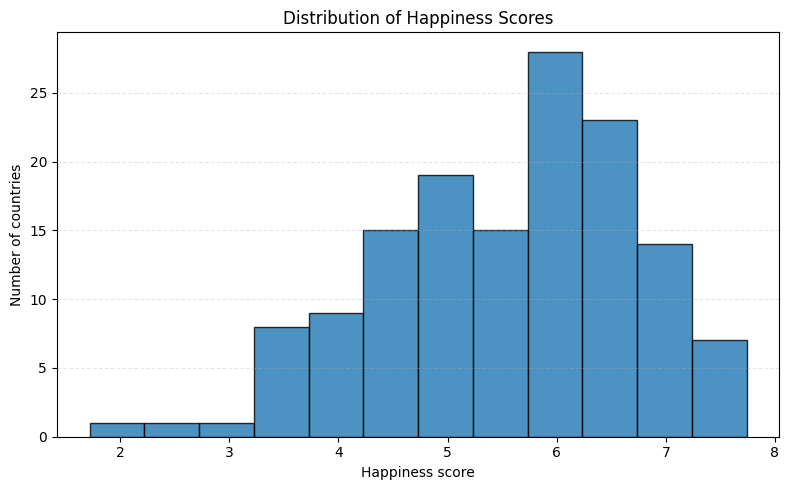

Top 10 happiest countries in the merged dataset:


,Country,Happiness,Rank
0,Finland,7.741,1
1,Denmark,7.583,2
2,Iceland,7.525,3
3,Sweden,7.344,4
4,Israel,7.341,5
5,Netherlands,7.319,6
6,Norway,7.302,7
7,Luxembourg,7.122,8
8,Switzerland,7.060,9
9,Australia,7.057,10


10 least happy countries in the merged dataset:


,Country,Happiness,Rank
0,Afghanistan,1.721,143
1,Lebanon,2.707,142
2,Lesotho,3.186,141
3,Sierra Leone,3.245,140
4,"Congo, Dem. Rep.",3.295,139
5,Zimbabwe,3.341,138
6,Botswana,3.383,137
7,Malawi,3.421,136
8,Eswatini,3.502,135
9,Zambia,3.502,134


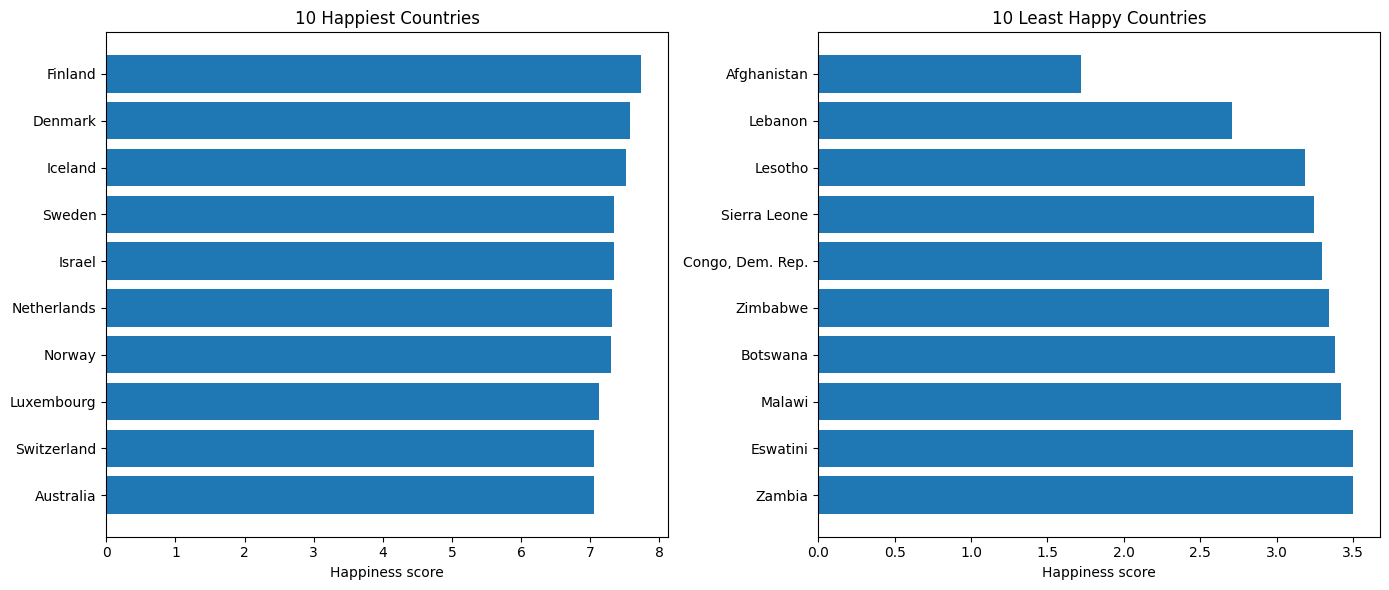

In [ ]:
happiness_data = df_merged.dropna(subset=["Happiness"]).copy()
happiness_data["Happiness"] = pd.to_numeric(happiness_data["Happiness"], errors="coerce")
happiness_data = happiness_data.dropna(subset=["Happiness"])

print("Happiness score summary:")
display(happiness_data["Happiness"].describe().to_frame(name="Happiness score").round(2))
print("Scores between 0 and 10:", bool(happiness_data["Happiness"].between(0, 10).all()))

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(happiness_data["Happiness"], bins=12, edgecolor="black", alpha=0.8)
ax.set_title("Distribution of Happiness Scores")
ax.set_xlabel("Happiness score")
ax.set_ylabel("Number of countries")
ax.grid(axis="y", linestyle="--", alpha=0.3)
fig.tight_layout()
plt.show()

top_happiest = happiness_data.nlargest(10, "Happiness").sort_values("Happiness")
least_happy = happiness_data.nsmallest(10, "Happiness").sort_values("Happiness", ascending=False)
print("Top 10 happiest countries in the merged dataset:")
display(top_happiest[["Country", "Happiness"] + (["Rank"] if "Rank" in top_happiest.columns else [])].sort_values("Happiness", ascending=False).reset_index(drop=True))
print("10 least happy countries in the merged dataset:")
display(least_happy[["Country", "Happiness"] + (["Rank"] if "Rank" in least_happy.columns else [])].sort_values("Happiness").reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(top_happiest["Country"], top_happiest["Happiness"])
axes[0].set_title("10 Happiest Countries")
axes[0].set_xlabel("Happiness score")
axes[1].barh(least_happy["Country"], least_happy["Happiness"])
axes[1].set_title("10 Least Happy Countries")
axes[1].set_xlabel("Happiness score")
fig.tight_layout()
plt.show()

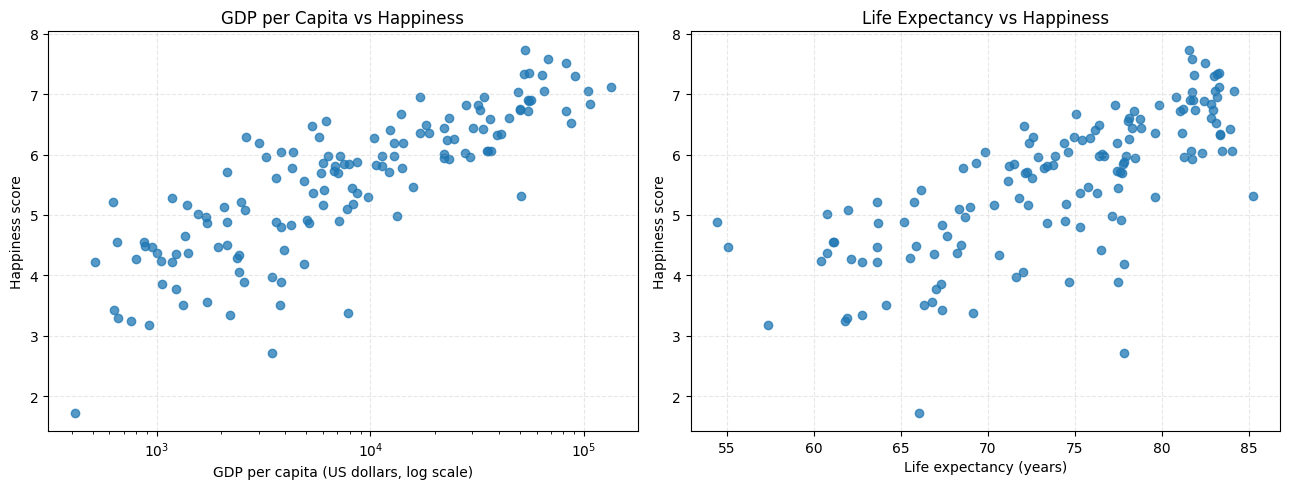

In [ ]:

relationship_data = df_merged.copy()
for column in ["Happiness", "GDP_per_capita", "Life_expectancy"]:
    relationship_data[column] = pd.to_numeric(relationship_data[column], errors="coerce")
relationship_data = relationship_data.dropna(subset=["Happiness", "GDP_per_capita", "Life_expectancy"])
relationship_data = relationship_data[relationship_data["GDP_per_capita"] > 0]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(relationship_data["GDP_per_capita"], relationship_data["Happiness"], alpha=0.75)
axes[0].set_xscale("log")
axes[0].set_title("GDP per Capita vs Happiness")
axes[0].set_xlabel("GDP per capita (US dollars, log scale)")
axes[0].set_ylabel("Happiness score")
axes[0].grid(True, linestyle="--", alpha=0.3)

axes[1].scatter(relationship_data["Life_expectancy"], relationship_data["Happiness"], alpha=0.75)
axes[1].set_title("Life Expectancy vs Happiness")
axes[1].set_xlabel("Life expectancy (years)")
axes[1].set_ylabel("Happiness score")
axes[1].grid(True, linestyle="--", alpha=0.3)
fig.tight_layout()
plt.show()

Number of countries by happiness level:


,Number of countries
Happiness_Level,
Low,31
Medium,55
High,55


Average indicators by happiness level:


,Population,GDP_per_capita,Life_expectancy,Happiness
Happiness_Level,,,,
Low,80829992.06,2027.39,66.82,3.84
Medium,60378856.67,7757.53,72.12,5.39
High,34382249.02,39658.28,79.77,6.64


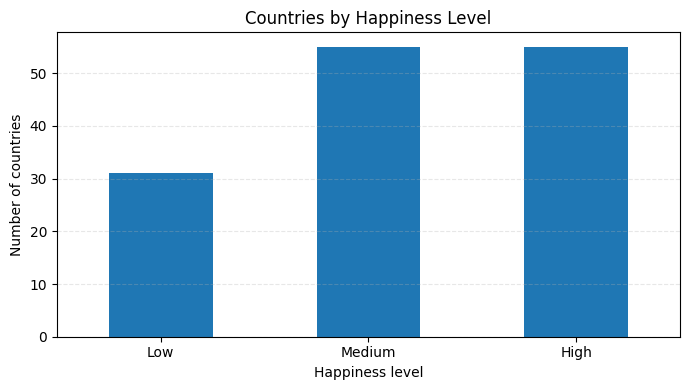

In [ ]:
if "Happiness_Level" not in df_merged.columns:
    df_merged["Happiness_Level"] = pd.cut(
        pd.to_numeric(df_merged["Happiness"], errors="coerce"),
        bins=[0, 4.5, 6, 10],
        labels=["Low", "Medium", "High"],
        include_lowest=True
    )

print("Number of countries by happiness level:")
level_counts = df_merged["Happiness_Level"].value_counts().reindex(["Low", "Medium", "High"], fill_value=0)
display(level_counts.to_frame(name="Number of countries"))

group_columns = [column for column in ["Population", "GDP_per_capita", "Life_expectancy", "Happiness"] if column in df_merged.columns]
group_means = df_merged.groupby("Happiness_Level", observed=False)[group_columns].mean().reindex(["Low", "Medium", "High"])
print("Average indicators by happiness level:")
display(group_means.round(2))

level_counts.plot(kind="bar", figsize=(7, 4), rot=0)
plt.title("Countries by Happiness Level")
plt.xlabel("Happiness level")
plt.ylabel("Number of countries")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
output_file = "countries_population_gdp_life_happiness_merged.csv"
df_merged.to_csv(output_file, index=False)
print(f"Merged analysis dataset saved to: {output_file}")
print("Final merged dataset shape:", df_merged.shape)
display(df_merged.head(10))